## 1. Importazioni e Setup

In [5]:
from scipy.stats import randint, uniform
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold


# --- Librerie Base e Data Manipulation ---
import numpy as np
import pandas as pd
import math as m
from tqdm import tqdm
from collections import Counter, defaultdict

# --- Visualizzazione ---
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from mpl_toolkits.mplot3d import Axes3D

# --- SciPy ---
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist, squareform
from scipy.stats import loguniform, uniform, randint

# --- Scikit-learn: Preprocessing e Imputazione ---
from sklearn.preprocessing import MinMaxScaler, StandardScaler, label_binarize
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

# --- Scikit-learn: Modelli (Classificazione e Regressione) ---
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV, Lasso, LassoCV
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.svm import SVC, SVR
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    BaggingRegressor,
    GradientBoostingClassifier,
    RandomForestClassifier,
    RandomForestRegressor,
)

# --- Gradient Boosting Libraries ---
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier, LGBMRegressor
from xgboost import XGBClassifier

# --- Clustering e Manifold Learning ---
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    DBSCAN,
    KMeans,
    OPTICS,
    cluster_optics_dbscan,
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# --- Outlier Detection (PyOD e Isolation Forest) ---
from pyod.models.abod import ABOD
from pyod.models.feature_bagging import FeatureBagging
from pyod.models.knn import KNN
from pyod.models.lof import LOF
from pyod.models.loda import LODA
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

# --- Model Selection e Pipeline ---
from sklearn.model_selection import (
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.combine import SMOTETomek

# --- Metriche ---
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
    roc_curve,
    auc,
    RocCurveDisplay,
    silhouette_samples,
    silhouette_score,
)


## 2. Caricamento Dataset

In [6]:
# dataset
df = pd.read_parquet("df_pulito.parquet")

# Train Test sii
pciat_cols = [f"PCIAT-PCIAT_{i:02d}" for i in range(1, 21)]
X = df.drop(columns=["sii", "risultati", "PCIAT-PCIAT_Total", "id"] + pciat_cols)
y = df["sii"]
X_train_nos, X_test_nos, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=222)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_nos)
X_test = scaler.transform(X_test_nos)

smote = SMOTETomek(random_state=222, n_jobs=-1)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)



In [7]:
def plot_roc_and_cm(estimator, X_test, y_test, model_name="Model"):
    """
    Visualizza la curva ROC multiclasse (One-vs-Rest) e la Confusion Matrix.
    """

    # ── ROC ──────────────────────────────────────────────────────────────────
    classes = np.unique(y_test)
    n_classes = len(classes)

    y_test_bin = label_binarize(y_test, classes=classes)

    if hasattr(estimator, "predict_proba"):
        y_score = estimator.predict_proba(X_test)
    elif hasattr(estimator, "decision_function"):
        y_score = estimator.decision_function(X_test)
    else:
        
        raise AttributeError("L'estimatore fornito non ha predict_proba o decision_function.")

    # Fix caso binario
    if n_classes == 2 and y_score.ndim > 1:
        y_score = y_score[:, 1]

    fpr, tpr, roc_auc = dict(), dict(), dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # Micro-average
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    # Macro-average
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    fpr["macro"], tpr["macro"] = all_fpr, mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    # Plot ROC
    plt.figure(figsize=(10, 8))
    plt.plot(fpr["micro"], tpr["micro"],
             label=f'Micro-average ROC (AUC = {roc_auc["micro"]:.2f})',
             color='deeppink', linestyle=':', linewidth=4)
    plt.plot(fpr["macro"], tpr["macro"],
             label=f'Macro-average ROC (AUC = {roc_auc["macro"]:.2f})',
             color='navy', linestyle=':', linewidth=4)

    colors = ['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple']
    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                 label=f'Classe {classes[i]} (AUC = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Curve ROC Multiclasse - {model_name}')
    plt.legend(loc="lower right")
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    # ── CONFUSION MATRIX ─────────────────────────────────────────────────────
    y_pred = estimator.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Classe Reale')
    plt.xlabel('Classe Predetta')
    plt.tight_layout()
    plt.show()


## SVM

In [8]:
# IPERPARAMETRI
# si usano valori che terminano con 1 perchè non ha senso considerare valori sullo stesso ordine di grandezza geometrico:
# Come formalizzato nei materiali didattici di riferimento, l'esplorazione ottimale dei parametri sensibili (inclusi 
# il parametro di costo C delle Support Vector Machines o i tassi di apprendimento) deve essere effettuata attraversando una scala 
# logaritmica pura (es. [0.001, 0.01, 0.1, 1, 10, 100, 1000]) per coprire spettri dimensionali reciprocamente distanti.
# Fonte Scientifica Esterna: Nel lavoro fondamentale di Yoshua Bengio, "Practical Recommendations for Gradient-Based Training of 
# Deep Architectures" (2012), viene dimostrato che il learning rate deve essere campionato applicando una trasformazione logaritmica, 
# definita dall'equazione η=10r, dove l'esponente r è una variabile casuale estratta uniformemente da un intervallo di interi o reali 
# (es. r∈[−4,−1]). I numeri come 0.1, 0.01 o 0.001 non sono altro che i risultati discreti determinati quando l'esponente r assume 
# valori interi pari a -1, -2 o -3.

param_dist_svm = {
    'C': [0.001, 0.01, 0.1, 1, 10], #, 100],
    'gamma': ['scale' , 'auto', 0.001, 0.01, 0.1, 1.0],
    'kernel': ['rbf'] # ,'poly', 'linear']
}
# 3. Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# 4. RandomizedSearchCV (30 iterazioni)
random_search_svm = RandomizedSearchCV(
    estimator=SVC(probability=True, random_state=222, class_weight='balanced'), # probability=True è necessario per calcolare le probabilità per la ROC curve,
    param_distributions=param_dist_svm,
    n_iter=20,
    scoring='f1_macro',   # Modifica: calcola la media non pesata (macro) degli F1-score di ogni classe
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=2
)
print("Avvio della RandomizedSearchCV per SVM...")
random_search_svm.fit(X_train, y_train)

# Risultati migliori
print(f"\nMigliori iperparametri trovati: {random_search_svm.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_svm.best_score_:.4f}")


Avvio della RandomizedSearchCV per SVM...
Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END .......................C=1, gamma=0.001, kernel=rbf; total time=  16.0s
[CV] END .......................C=1, gamma=0.001, kernel=rbf; total time=  16.0s
[CV] END .......................C=1, gamma=0.001, kernel=rbf; total time=  16.4s
[CV] END .......................C=1, gamma=0.001, kernel=rbf; total time=  16.4s
[CV] END .......................C=1, gamma=0.001, kernel=rbf; total time=  16.5s
[CV] END ......................C=0.01, gamma=0.1, kernel=rbf; total time=  19.4s
[CV] END ......................C=0.01, gamma=0.1, kernel=rbf; total time=  19.8s
[CV] END ......................C=0.01, gamma=0.1, kernel=rbf; total time=  20.5s
[CV] END ......................C=0.01, gamma=0.1, kernel=rbf; total time=  21.0s
[CV] END ......................C=0.01, gamma=0.1, kernel=rbf; total time=  21.3s
[CV] END ........................C=10, gamma=1.0, kernel=rbf; total time=  21.2s
[CV] 

Accuracy sul Test Set: 0.5199
F1-score per classe: [0.67200557 0.35418502 0.31207598 0.02083333]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.82      0.57      0.67      1689
           1       0.30      0.43      0.35       469
           2       0.25      0.40      0.31       284
           3       0.01      0.08      0.02        26

    accuracy                           0.52      2468
   macro avg       0.35      0.37      0.34      2468
weighted avg       0.64      0.52      0.56      2468

Risultati del tuning salvati in 'svm_random_search_results.csv'


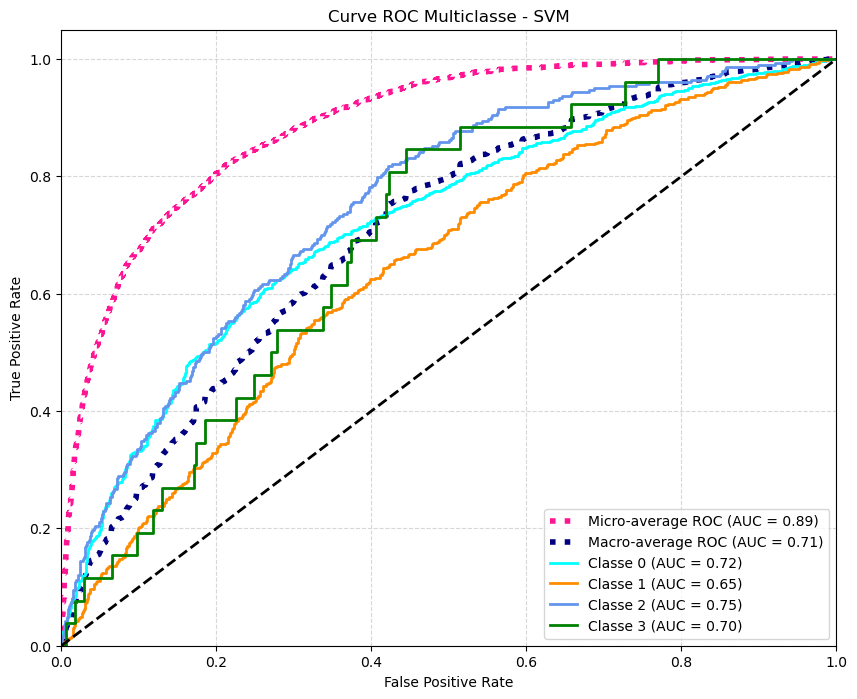

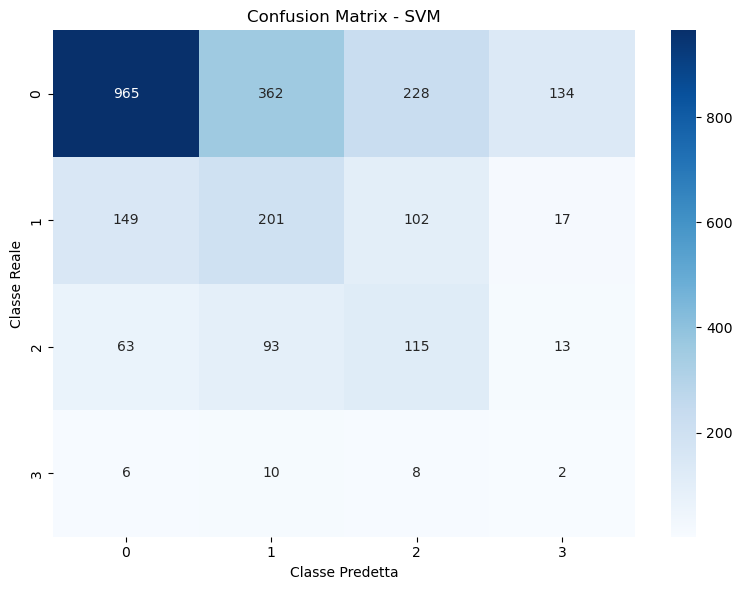

In [9]:
# Valutazione sul Test Set reale
best_svm = random_search_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_svm))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_svm, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_svm))

# Salvataggio dei risultati in CSV
svm_results_df = pd.DataFrame(random_search_svm.cv_results_)
#svm_results_df.to_csv("csv_classificazione/svm_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'svm_random_search_results.csv'")

# Visualizzazione della curva ROC
plot_roc_and_cm(best_svm, X_test, y_test, 'SVM')


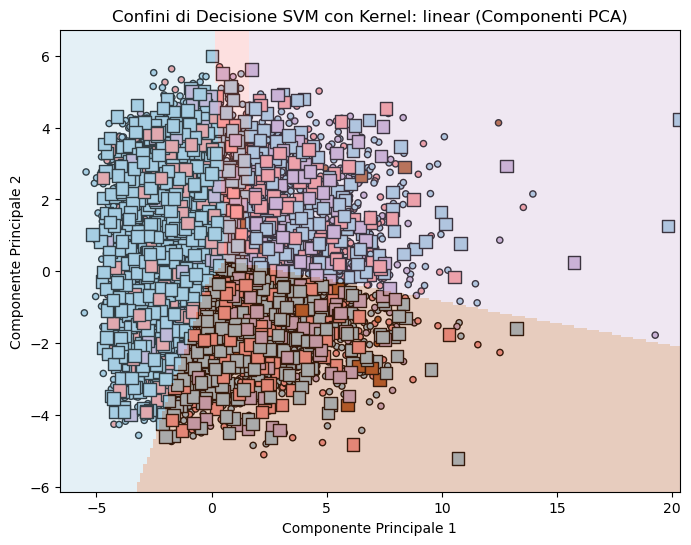

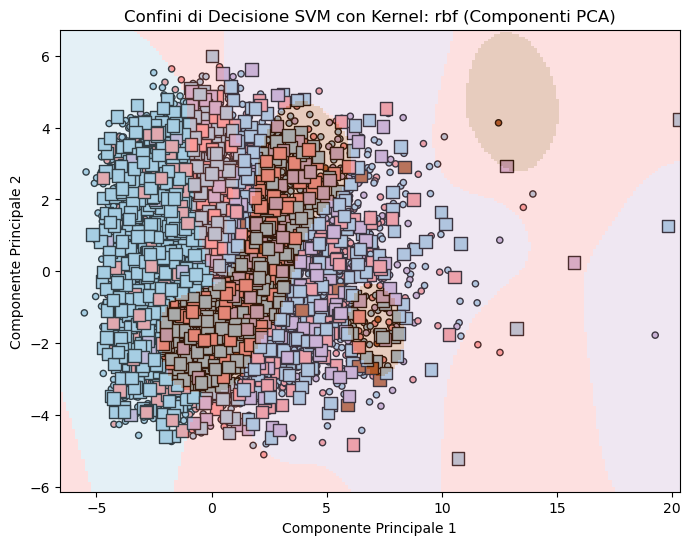

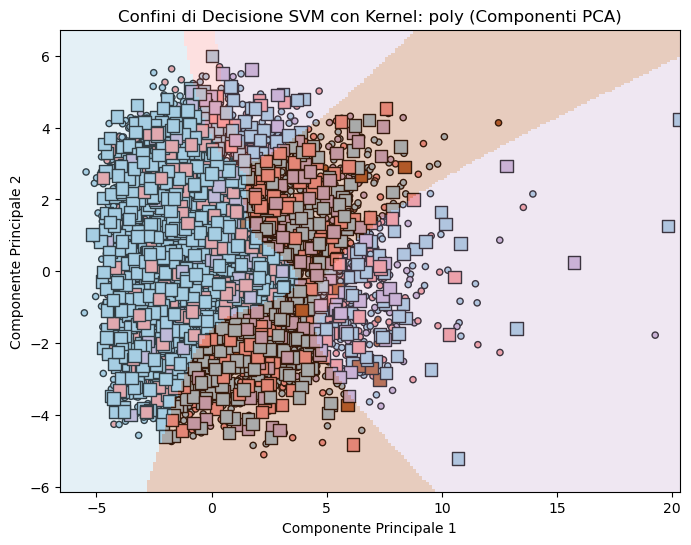

In [10]:
# Visualizzazione dei confini di decisione in 2D tramite PCA (esemplificazione)
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train) 
X_test_pca = pca.transform(X_test)

x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
XX, YY = np.mgrid[x_min:x_max:200j, y_min:y_max:200j]

for kernel in ('linear', 'rbf', 'poly'):
    # Addestriamo la SVM sulle sole 2 componenti PCA per la visualizzazione grafica
    clf_pca = SVC(kernel=kernel, C=1.8, gamma='scale', class_weight='balanced', random_state=222)
    clf_pca.fit(X_train_pca, y_train)

    plt.figure(figsize=(8, 6))
    
    # Punti di Training (cerchi piccoli) e Test (quadrati grandi)
    plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap=plt.cm.Paired, edgecolors='k', s=20)
    plt.scatter(X_test_pca[:, 0], X_test_pca[:, 1], c=y_test, cmap=plt.cm.Paired, edgecolors='k', s=80, marker='s')

    # Predizione sulla griglia 2D
    Z = clf_pca.predict(np.c_[XX.ravel(), YY.ravel()])
    Z = Z.reshape(XX.shape)

    plt.pcolormesh(XX, YY, Z, cmap=plt.cm.Paired, alpha=0.3, shading='auto')
    plt.title(f'Confini di Decisione SVM con Kernel: {kernel} (Componenti PCA)')
    plt.xlabel('Componente Principale 1')
    plt.ylabel('Componente Principale 2')
    plt.show()


## RandomForest

In [11]:
param_dist_rf = {
    'n_estimators':      [100, 150, 200, 250, 300], #, 400, 450, 500, 600, 700],
    'max_depth':         [None],#, 15, 20, 30], #gli alberi di una Random Forest devono essere unpruned (non potati), lasciati liberi di crescere fino a quando ogni foglia è pura. Limitare la profondità a 6 o 7 introduce un bias artificiale sull'induttore di base, forzando la foresta a lavorare con weak classifiers troppo deboli.
    'min_samples_split': [2, 5, 8, 9, 10, 11, 12, 15],
    'min_samples_leaf':  [1, 2, 3, 4, 8],
    'criterion':         ['gini', 'entropy'],
    'max_features':      ['sqrt', 'log2'],
    'class_weight':      ['balanced', 'balanced_subsample'] # altri valori neanche li considero
}

# 3. StratifiedKFold (Invariata)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# 4. RandomizedSearchCV (Applicata alla pipeline con i parametri corretti)
random_search_rf = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=222, n_jobs=-1),
    param_distributions=param_dist_rf, # Utilizza il dizionario corretto
    n_iter=30,
    scoring='f1_macro',   # Modifica: calcola la media non pesata (macro) degli F1-score di ogni classe
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=2
)

print("Avvio della RandomizedSearchCV per Random Forest...")
random_search_rf.fit(X_train, y_train)

# Risultati migliori
print(f"\nMigliori iperparametri trovati: {random_search_rf.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_rf.best_score_:.4f}")


Avvio della RandomizedSearchCV per Random Forest...
Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=3, min_samples_split=9, n_estimators=100; total time=   1.2s
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=3, min_samples_split=9, n_estimators=100; total time=   1.2s
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=3, min_samples_split=9, n_estimators=100; total time=   1.3s
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=3, min_samples_split=9, n_estimators=100; total time=   1.3s
[CV] END class_weight=balanced_subsample, criterion=entropy, max_depth=None, max_features=log2, min_samples_leaf=3, min_samples_split=9, n_estimators=100; total time=   1.7s
[CV] END class_w

Accuracy sul Test Set: 0.6159
F1-score per classe: [0.76639953 0.28733032 0.32371795 0.03389831]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.77      0.76      0.77      1689
           1       0.31      0.27      0.29       469
           2       0.30      0.36      0.32       284
           3       0.03      0.04      0.03        26

    accuracy                           0.62      2468
   macro avg       0.35      0.36      0.35      2468
weighted avg       0.62      0.62      0.62      2468

Risultati del tuning salvati in 'rf_af_halving_search_results.csv'


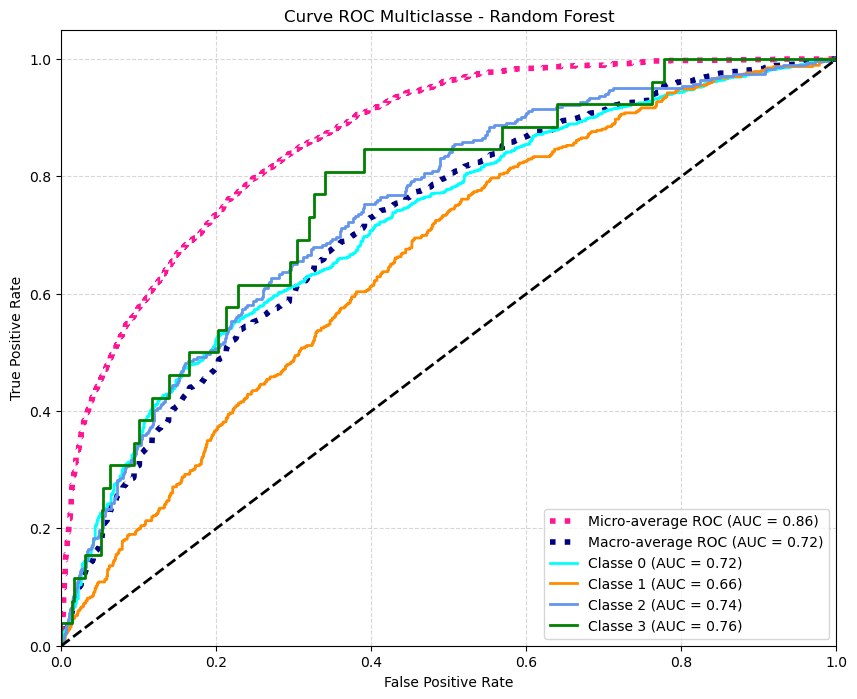

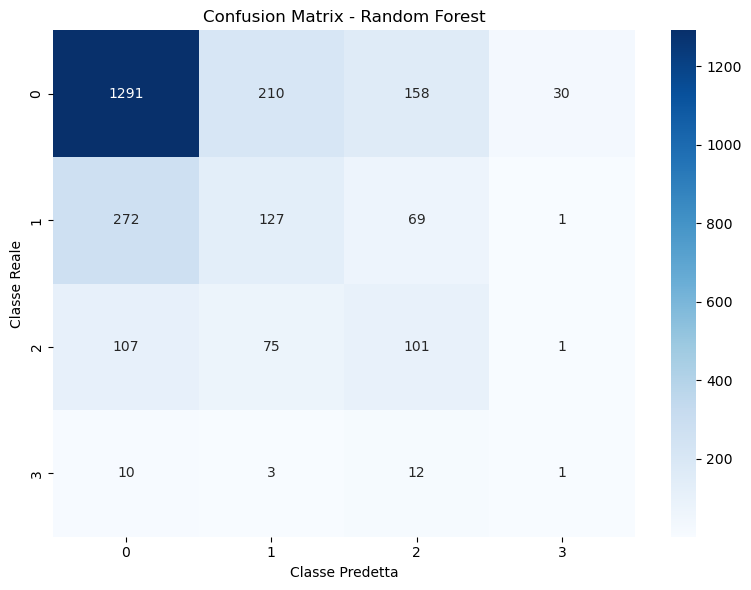

In [12]:
# Valutazione sul Test Set
# valori oltre al 300 di n estimator aumentano solo il carico computazionale e migliorano di pochissimo i risultati
best_rf = random_search_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_rf))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_rf, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_rf))

rf_results_df = pd.DataFrame(random_search_rf.cv_results_)
#rf_results_df.to_csv("csv_classificazione/rf_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'rf_af_halving_search_results.csv'")
plot_roc_and_cm(best_rf, X_test, y_test, "Random Forest")


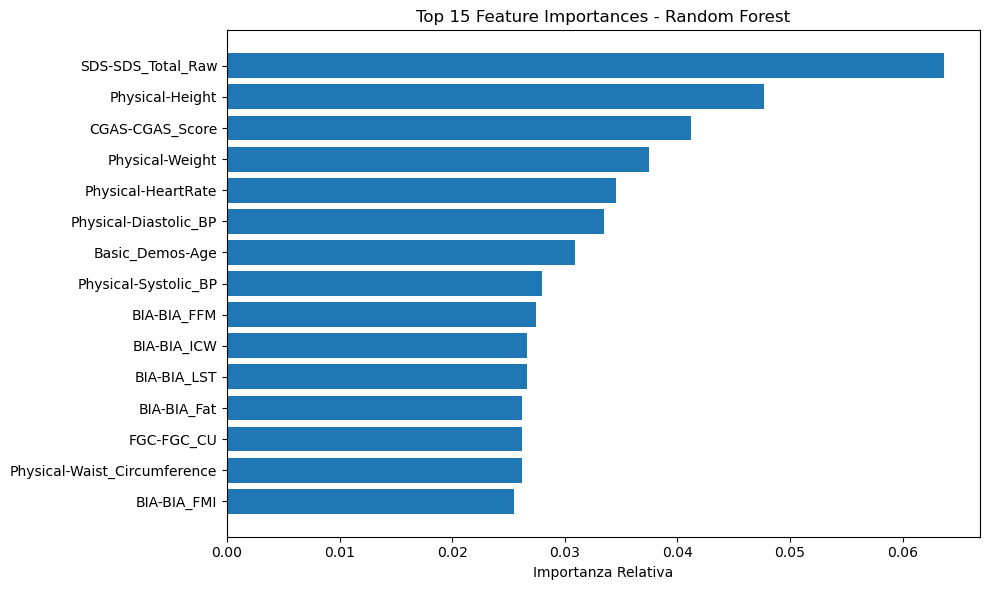

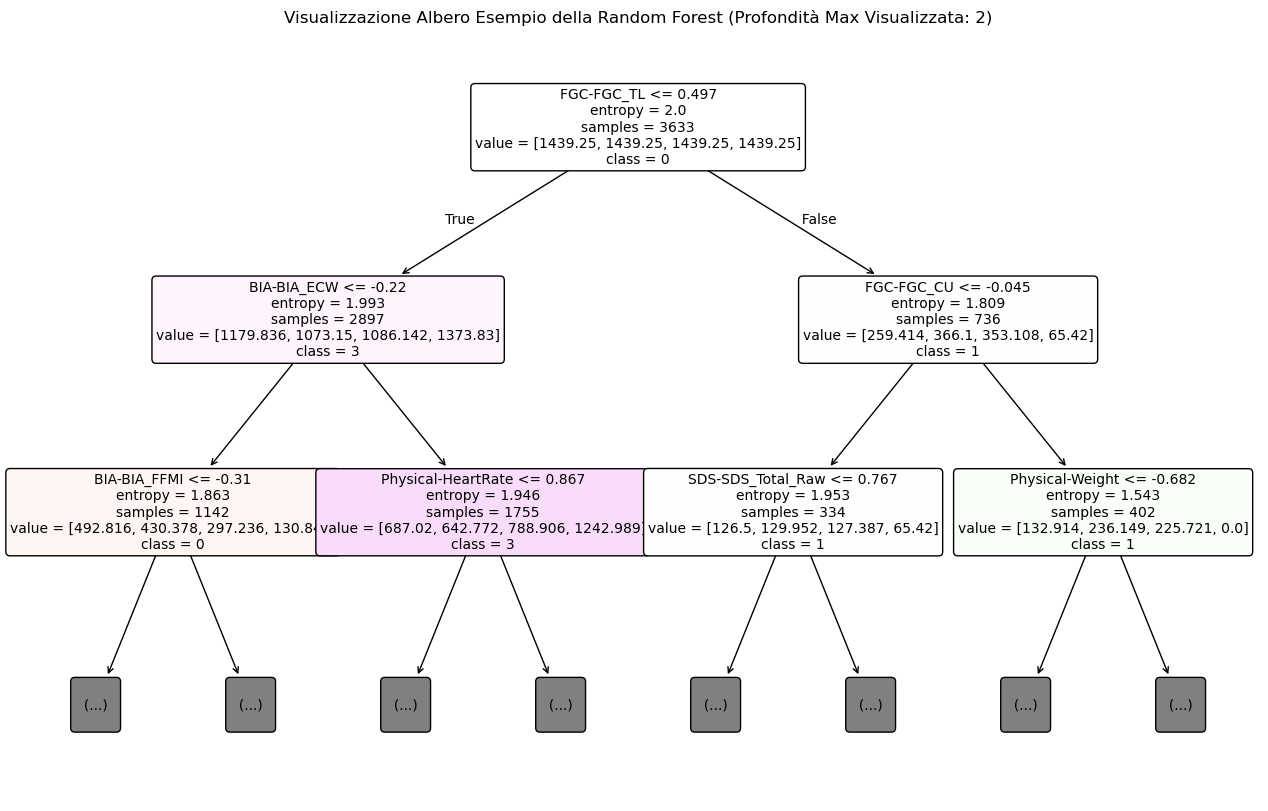

In [13]:
nbr_features = 15
tree_feature_importances = best_rf.feature_importances_
sorted_idx = tree_feature_importances.argsort()[-nbr_features:]

feature_names = np.array(X.columns)

plt.figure(figsize=(10, 6))
plt.barh(np.arange(len(sorted_idx)), tree_feature_importances[sorted_idx])
plt.yticks(np.arange(len(sorted_idx)), feature_names[sorted_idx])
plt.title(f'Top {nbr_features} Feature Importances - Random Forest')
plt.xlabel('Importanza Relativa')
plt.tight_layout()
plt.show()

# Visualizzazione di un singolo albero estratto direttamente dalla foresta
plt.figure(figsize=(16, 10))
plot_tree(
    best_rf.estimators_[0],
    feature_names=feature_names,
    class_names=[str(c) for c in np.unique(y)],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=2
)
plt.title("Visualizzazione Albero Esempio della Random Forest (Profondità Max Visualizzata: 2)")
plt.show()


## Bagging

In [14]:
# ho provato prima a provare la grid anche per il randomforest ma esce stranamente meglio con i valori predefiniti

param_dist_bagging = {
    "n_estimators": [50, 80, 100, 150],
    "max_samples": [0.7, 0.8, 0.9],
    "max_features": [0.5, 0.8, 0.9],
}

# 3. StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# 4. RandomizedSearchCV
random_search_bagging = RandomizedSearchCV(
    estimator=BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=222, class_weight="balanced"),
        random_state=222),
    param_distributions=param_dist_bagging,
    n_iter=20,
    scoring='f1_macro',   # Modifica: calcola la media non pesata (macro) degli F1-score di ogni classe
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=1
)

print("Avvio della RandomizedSearchCV per Bagging Classifier...")
random_search_bagging.fit(X_train, y_train)

# Risultati migliori
print(f"\nMigliori iperparametri trovati: {random_search_bagging.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_bagging.best_score_:.4f}")


Avvio della RandomizedSearchCV per Bagging Classifier...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Migliori iperparametri trovati: {'n_estimators': 50, 'max_samples': 0.9, 'max_features': 0.9}
Miglior F1-macro in Cross-Validation: 0.2404


Accuracy sul Test Set: 0.6880
F1-score per classe: [0.81766871 0.07662835 0.07051282 0.07407407]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.70      0.99      0.82      1689
           1       0.38      0.04      0.08       469
           2       0.39      0.04      0.07       284
           3       1.00      0.04      0.07        26

    accuracy                           0.69      2468
   macro avg       0.62      0.28      0.26      2468
weighted avg       0.61      0.69      0.58      2468

Risultati del tuning salvati in 'bagging_random_search_results.csv'


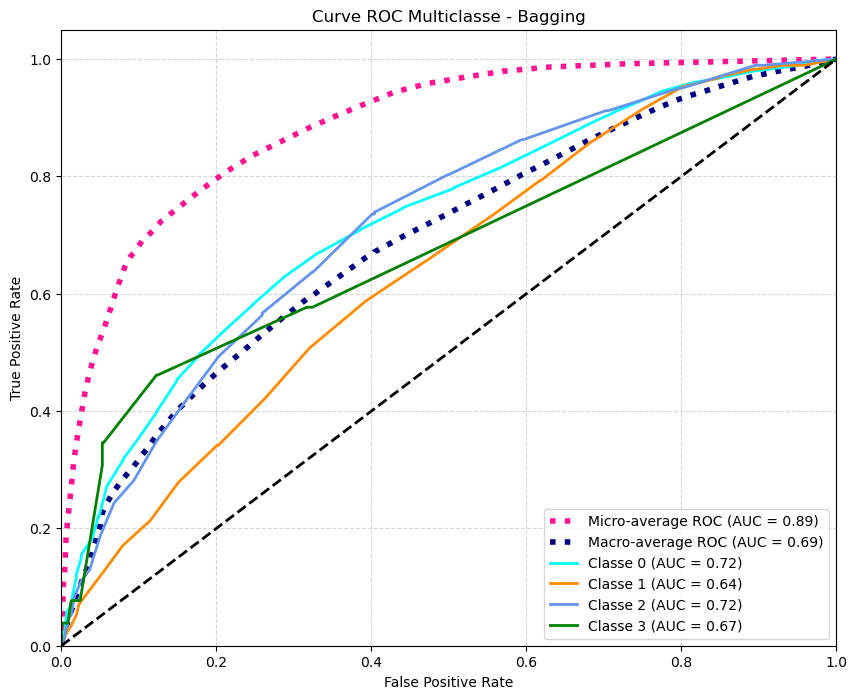

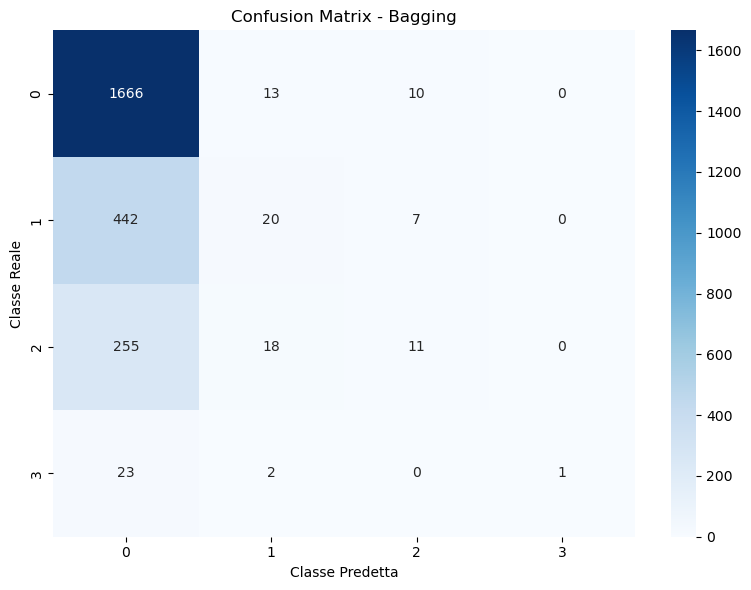

In [15]:
# Valutazione sul Test Set reale
best_bagging = random_search_bagging.best_estimator_
y_pred_bagging = best_bagging.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_bagging))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_bagging, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_bagging))

# Salvataggio dei risultati in CSV
bagging_results_df = pd.DataFrame(random_search_bagging.cv_results_)
#bagging_results_df.to_csv("csv_classificazione/bagging_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'bagging_random_search_results.csv'")

# ROC and CM
plot_roc_and_cm(random_search_bagging, X_test, y_test, "Bagging")


## AdaBoost

In [16]:
#tecnicamente adaboost è per le binarie ma viene usato l'algoritmo SAMME

# CORREZIONE METODOLOGICA: SMOTETomek dentro la pipeline del fold di CV.
# Il problema precedente era che SMOTE veniva applicato all'intero train set
# prima della CV, causando data leakage: i campioni sintetici finivano sia nel
# fold di train che in quello di validazione, gonfiando artificialmente il CV score.
# Soluzione: ImbPipeline applica SMOTE SOLO al fold di training ad ogni split,
# mai al fold di validazione. In questo modo il CV score è onesto.

param_grid_adaboost = {
    # Prefisso "classifier__" perché il modello è avvolto in ImbPipeline
    # Ridotta la griglia per velocizzare: 3x3 = 9 combinazioni (GridSearch esaustivo)
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.1, 0.5, 1.0],
    # max_depth dell'estimatore base nella pipeline
    'classifier__estimator__max_depth': [1, 2],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=222)

# ImbPipeline (da imblearn): gestisce correttamente il resampling step-by-step.
# Ad ogni fold: (1) SMOTE su train fold → (2) fit AdaBoost → (3) score su val fold.
pipeline_adaboost = ImbPipeline([
    ('smote', SMOTETomek(random_state=222, n_jobs=-1)),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=222),
        random_state=222
    ))
])

grid_search_adaboost = GridSearchCV(
    estimator=pipeline_adaboost,
    param_grid=param_grid_adaboost,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Avvio GridSearchCV per AdaBoost (SMOTETomek in-fold)...")
grid_search_adaboost.fit(X_train, y_train)  # X_train NON ricampionato: ci pensa la pipeline

print("\n" + "="*40)
print(f"Migliori iperparametri trovati:\n{grid_search_adaboost.best_params_}")
print(f"Miglior F1-macro in CV: {grid_search_adaboost.best_score_:.4f}")
print("="*40)


Avvio GridSearchCV per AdaBoost (SMOTETomek in-fold)...
Fitting 3 folds for each of 18 candidates, totalling 54 fits

Migliori iperparametri trovati:
{'classifier__estimator__max_depth': 2, 'classifier__learning_rate': 0.5, 'classifier__n_estimators': 200}
Miglior F1-macro in CV: 0.3313


In [17]:
from imblearn.over_sampling import ADASYN
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import CondensedNearestNeighbour
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# ---------------------------------------------------------------------------
# PIPELINE DINAMICA
# 'passthrough' è un segnaposto che indica a scikit-learn/imblearn 
# di lasciare quello step vuoto in fase di inizializzazione. 
# Verrà riempito iterativamente dalla GridSearchCV.
# ---------------------------------------------------------------------------
pipeline_adaboost = ImbPipeline([
    ('resampler', 'passthrough'), 
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=222),
        random_state=222,
        algorithm='SAMME'
    ))
])

# ---------------------------------------------------------------------------
# SPAZIO DEI PARAMETRI COMPLETO
# La grid valuterà dinamicamente le tre tecniche di resampling in-fold.
# ---------------------------------------------------------------------------
param_grid_adaboost = {
    'resampler': [
        SMOTETomek(random_state=222, n_jobs=-1),
        ADASYN(random_state=222), 
        CondensedNearestNeighbour(random_state=222, n_jobs=-1)
    ],
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.1, 0.5, 1.0],
    'classifier__estimator__max_depth': [1, 2],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=222)

# Spazio totale: 54 combinazioni (162 fit totali)
grid_search_adaboost = GridSearchCV(
    estimator=pipeline_adaboost,
    param_grid=param_grid_adaboost,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Avvio GridSearchCV: Confronto SMOTE vs ADASYN vs CNN in-fold...")
grid_search_adaboost.fit(X_train, y_train)

print("\n" + "="*50)
print(f"Miglior tecnica e iperparametri:\n{grid_search_adaboost.best_params_}")
print(f"Miglior F1-macro in CV: {grid_search_adaboost.best_score_:.4f}")
print("="*50)


Avvio GridSearchCV: Confronto SMOTE vs ADASYN vs CNN in-fold...
Fitting 3 folds for each of 54 candidates, totalling 162 fits


/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorith


Miglior tecnica e iperparametri:
{'classifier__estimator__max_depth': 2, 'classifier__learning_rate': 0.5, 'classifier__n_estimators': 200, 'resampler': SMOTETomek(n_jobs=-1, random_state=222)}
Miglior F1-macro in CV: 0.3313


Accuracy sul Test Set: 0.5199
F1-score per classe: [0.6760013  0.3002681  0.26010545 0.03389831]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.75      0.61      0.68      1689
           1       0.26      0.36      0.30       469
           2       0.26      0.26      0.26       284
           3       0.02      0.12      0.03        26

    accuracy                           0.52      2468
   macro avg       0.32      0.34      0.32      2468
weighted avg       0.59      0.52      0.55      2468

Risultati del tuning salvati in 'adaboost_random_search_results.csv'


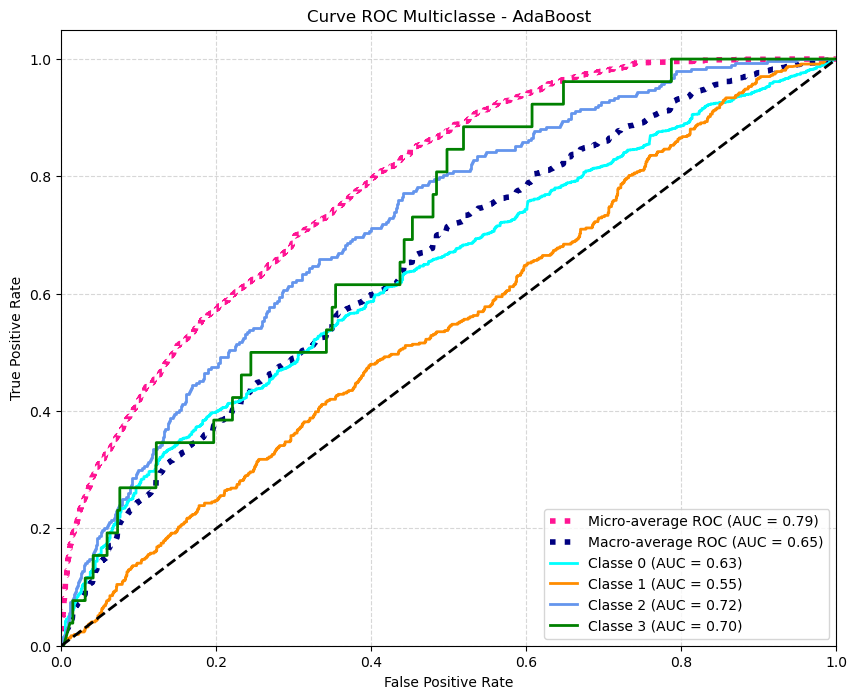

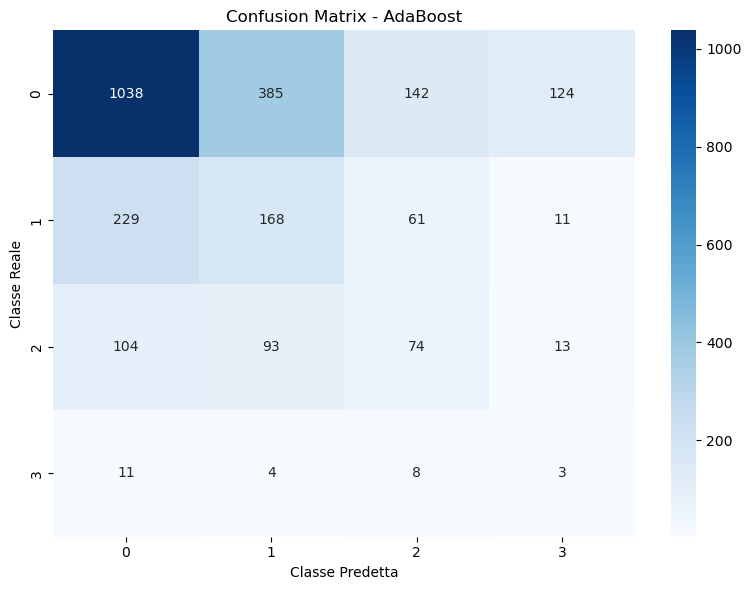

In [18]:
# best_estimator_ è ora una ImbPipeline.
# La pipeline esegue predict su X_test senza applicare SMOTE (corretto: 
# SMOTE si applica solo in training, mai in inferenza).
best_adaboost = grid_search_adaboost.best_estimator_
y_pred_adaboost = best_adaboost.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_adaboost))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_adaboost, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_adaboost))

# Salvataggio dei risultati in CSV
adaboost_results_df = pd.DataFrame(grid_search_adaboost.cv_results_)
#adaboost_results_df.to_csv("csv_classificazione/adaboost_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'adaboost_random_search_results.csv'")

# plot_roc_and_cm riceve la pipeline intera: usa pipeline.predict_proba(X_test)
# che internamente chiama il classificatore finale (l'unico step con predict_proba).
plot_roc_and_cm(best_adaboost, X_test, y_test, "AdaBoost")


### AdaBoost senza Resampling
Eseguiamo la stessa ricerca iperparametrica ma senza utilizzare tecniche di over/undersampling nella pipeline (disabilitando il resampler impostandolo a `'passthrough'`).

In [19]:
# --- ADABOOST SENZA RESAMPLING ---
pipeline_adaboost_no_resample = ImbPipeline([
    ('resampler', 'passthrough'), 
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=222),
        random_state=222,
        algorithm='SAMME'
    ))
])

param_grid_adaboost_no_resample = {
    'resampler': ['passthrough'],
    'classifier__n_estimators': [100, 200, 300],
    'classifier__learning_rate': [0.1, 0.5, 1.0],
    'classifier__estimator__max_depth': [1, 2],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=222)

grid_search_adaboost_no_resample = GridSearchCV(
    estimator=pipeline_adaboost_no_resample,
    param_grid=param_grid_adaboost_no_resample,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

print("Avvio GridSearchCV AdaBoost (Senza Resampling)...")
grid_search_adaboost_no_resample.fit(X_train, y_train)

print("\n" + "="*50)
print(f"Migliori iperparametri trovati:\n{grid_search_adaboost_no_resample.best_params_}")
print(f"Miglior F1-macro in CV: {grid_search_adaboost_no_resample.best_score_:.4f}")
print("="*50)


Avvio GridSearchCV AdaBoost (Senza Resampling)...
Fitting 3 folds for each of 18 candidates, totalling 54 fits


/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorith


Migliori iperparametri trovati:
{'classifier__estimator__max_depth': 2, 'classifier__learning_rate': 1.0, 'classifier__n_estimators': 300, 'resampler': 'passthrough'}
Miglior F1-macro in CV: 0.3071


Accuracy sul Test Set (Senza Resampling): 0.6665
F1-score per classe: [0.80517423 0.21142857 0.21800948 0.        ]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.73      0.90      0.81      1689
           1       0.32      0.16      0.21       469
           2       0.33      0.16      0.22       284
           3       0.00      0.00      0.00        26

    accuracy                           0.67      2468
   macro avg       0.35      0.31      0.31      2468
weighted avg       0.60      0.67      0.62      2468



/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


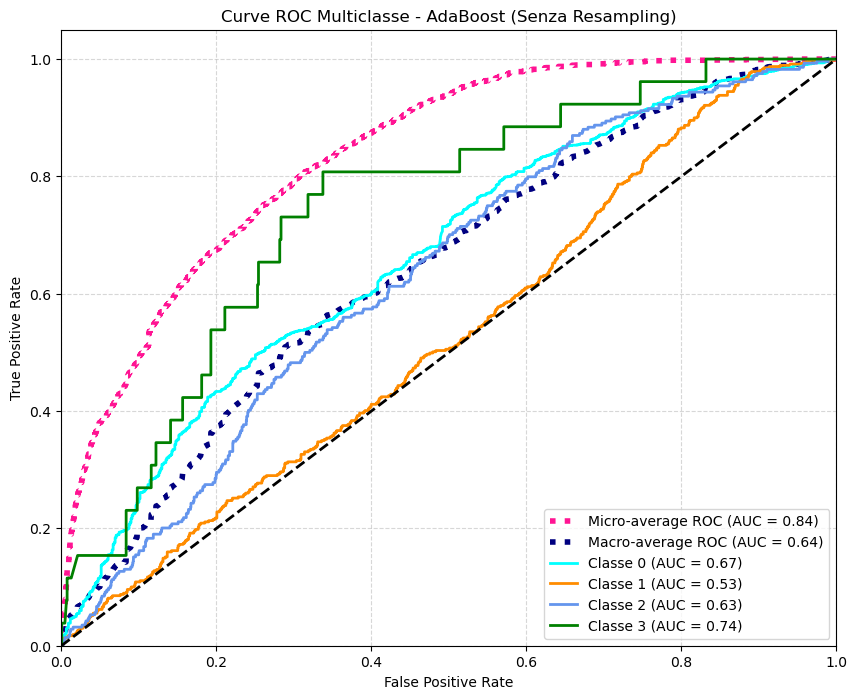

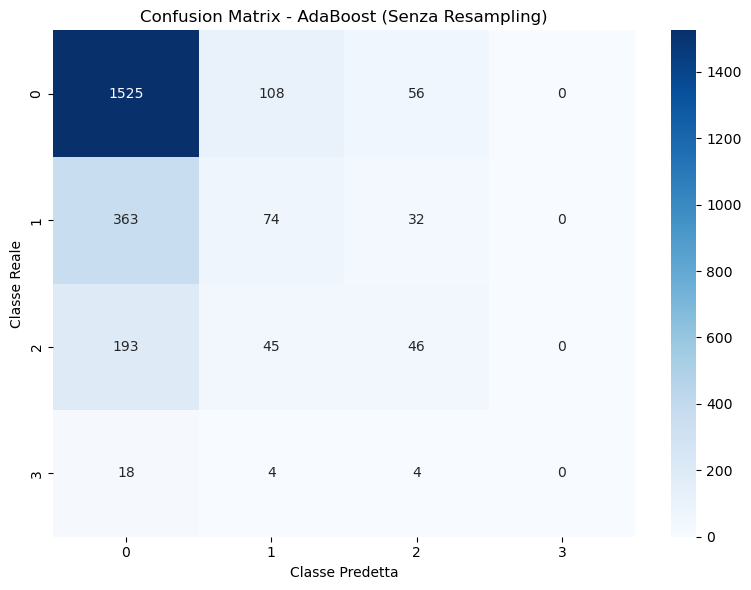

In [20]:
# Valutazione sul Test Set reale (Senza Resampling)
best_adaboost_no_resample = grid_search_adaboost_no_resample.best_estimator_
y_pred_adaboost_no_resample = best_adaboost_no_resample.predict(X_test)

print("Accuracy sul Test Set (Senza Resampling): %.4f" % accuracy_score(y_test, y_pred_adaboost_no_resample))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_adaboost_no_resample, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_adaboost_no_resample))

plot_roc_and_cm(best_adaboost_no_resample, X_test, y_test, "AdaBoost (Senza Resampling)")


## GradientBoosting

In [21]:
from imblearn.combine import SMOTETomek
# CORREZIONE METODOLOGICA: SMOTETomek dentro la pipeline del fold di CV.
# Stessa logica di AdaBoost: ImbPipeline garantisce che SMOTE venga applicato
# solo al fold di train ad ogni split, evitando il leakage che gonfiava il CV
# score precedente fino a 0.85 pur avendo un test F1-macro reale di ~0.34.

# --- SPAZIO PARAMETRI REGOLARIZZATO CONTRO L'OVERFITTING ---
# learning_rate basso + n_estimators moderati = shrinkage corretto.
# Rimossi valori aggressivi (0.5) che causano memorizzazione rapida del noise.
# max_leaf_nodes [4,8]: alberi poco profondi, basso bias ma bassa varianza.
# subsample < 1.0 + max_features: doppia stocasticità per decorrelazione.
param_dist_gb = {
    'classifier__n_estimators': [50, 100, 150],
    'classifier__learning_rate': [0.05, 0.1, 0.2],
    'classifier__max_leaf_nodes': [4, 8],
    'classifier__subsample': [0.7, 0.9],
    'classifier__max_features': ['sqrt', 0.8],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=222)

pipeline_gb = ImbPipeline([
    ('smote', SMOTETomek(random_state=222, n_jobs=-1)),
    ('classifier', GradientBoostingClassifier(random_state=222))
])

# n_iter=10: con 5 parametri e spazio ~3x3x2x2x2=72 combinazioni,
# 10 iterazioni random coprono ~14% dello spazio in pochi secondi.
random_search_gb = RandomizedSearchCV(
    estimator=pipeline_gb,
    param_distributions=param_dist_gb,
    n_iter=10,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=1
)

print("Avvio della RandomizedSearchCV per Gradient Boosting (SMOTETomek in-fold)...")
random_search_gb.fit(X_train, y_train)  # X_train NON ricampionato: ci pensa la pipeline

print("\n" + "="*40)
print(f"Migliori iperparametri trovati:\n{random_search_gb.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_gb.best_score_:.4f}")
print("="*40 + "\n")


Avvio della RandomizedSearchCV per Gradient Boosting (SMOTETomek in-fold)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Migliori iperparametri trovati:
{'classifier__subsample': 0.7, 'classifier__n_estimators': 50, 'classifier__max_leaf_nodes': 8, 'classifier__max_features': 'sqrt', 'classifier__learning_rate': 0.2}
Miglior F1-macro in Cross-Validation: 0.3393



Accuracy sul Test Set: 0.6029
F1-score per classe: [0.75386861 0.24539877 0.32423208 0.03636364]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.74      0.76      0.75      1689
           1       0.29      0.21      0.25       469
           2       0.31      0.33      0.32       284
           3       0.02      0.08      0.04        26

    accuracy                           0.60      2468
   macro avg       0.34      0.35      0.34      2468
weighted avg       0.60      0.60      0.60      2468

Risultati del tuning salvati in 'gradient_boosting_random_search_results.csv'


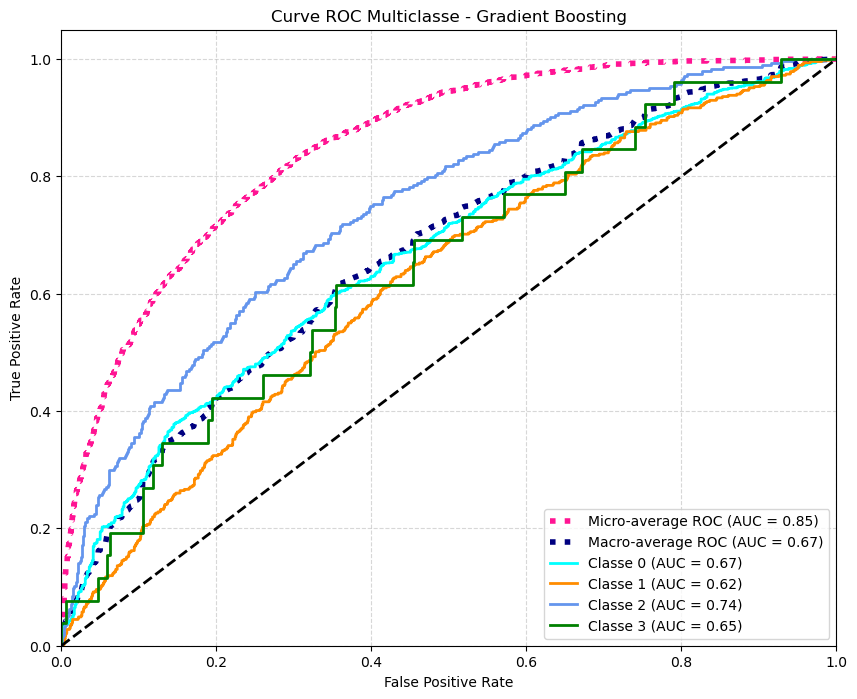

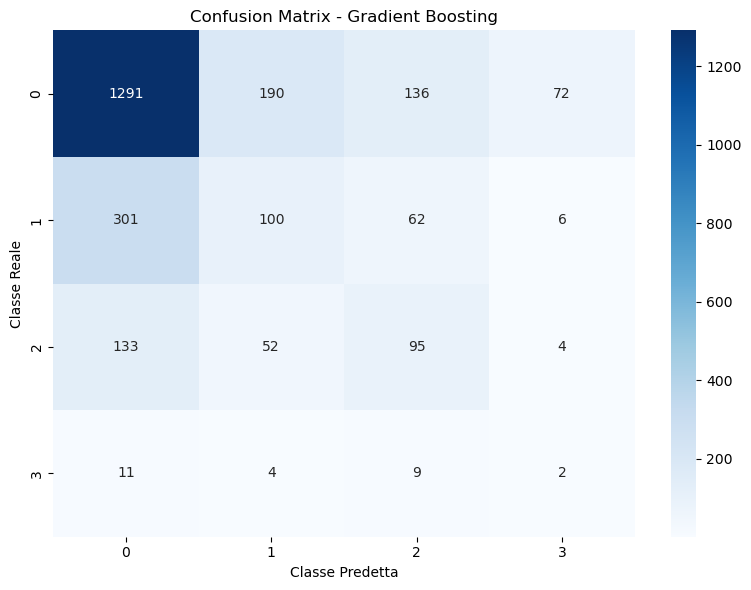

In [22]:
# Valutazione sul Test Set reale
# best_estimator_ è una ImbPipeline: predict su X_test non applica SMOTE.
best_gb = random_search_gb.best_estimator_
y_pred_gb = best_gb.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_gb))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_gb, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_gb))

# Salvataggio dei risultati in CSV
gb_results_df = pd.DataFrame(random_search_gb.cv_results_)
#gb_results_df.to_csv("csv_classificazione/gradient_boosting_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'gradient_boosting_random_search_results.csv'")

plot_roc_and_cm(best_gb, X_test, y_test, "Gradient Boosting")


### Gradient Boosting senza Resampling
Eseguiamo la stessa ricerca iperparametrica ma senza utilizzare tecniche di oversampling nella pipeline (impostando lo step `smote` a `'passthrough'`).

In [23]:
# --- GRADIENT BOOSTING SENZA RESAMPLING ---
pipeline_gb_no_resample = ImbPipeline([     ('smote', 'passthrough'),     ('classifier', GradientBoostingClassifier(random_state=222)) ])

random_search_gb_no_resample = RandomizedSearchCV(
    estimator=pipeline_gb_no_resample,
    param_distributions=param_dist_gb,
    n_iter=10,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=1
)

print("Avvio della RandomizedSearchCV per Gradient Boosting (Senza Resampling)...")
random_search_gb_no_resample.fit(X_train, y_train)

print("\n" + "="*40)
print(f"Migliori iperparametri trovati:\n{random_search_gb_no_resample.best_params_}")
print(f"Miglior F1-macro in Cross-Validation: {random_search_gb_no_resample.best_score_:.4f}")
print("="*40 + "\n")


Avvio della RandomizedSearchCV per Gradient Boosting (Senza Resampling)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Migliori iperparametri trovati:
{'classifier__subsample': 0.9, 'classifier__n_estimators': 150, 'classifier__max_leaf_nodes': 8, 'classifier__max_features': 0.8, 'classifier__learning_rate': 0.2}
Miglior F1-macro in Cross-Validation: 0.3111



Accuracy sul Test Set (Senza Resampling): 0.6787
F1-score per classe: [0.8159204  0.20238095 0.24078624 0.        ]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.73      0.92      0.82      1689
           1       0.33      0.14      0.20       469
           2       0.40      0.17      0.24       284
           3       0.00      0.00      0.00        26

    accuracy                           0.68      2468
   macro avg       0.37      0.31      0.31      2468
weighted avg       0.61      0.68      0.62      2468



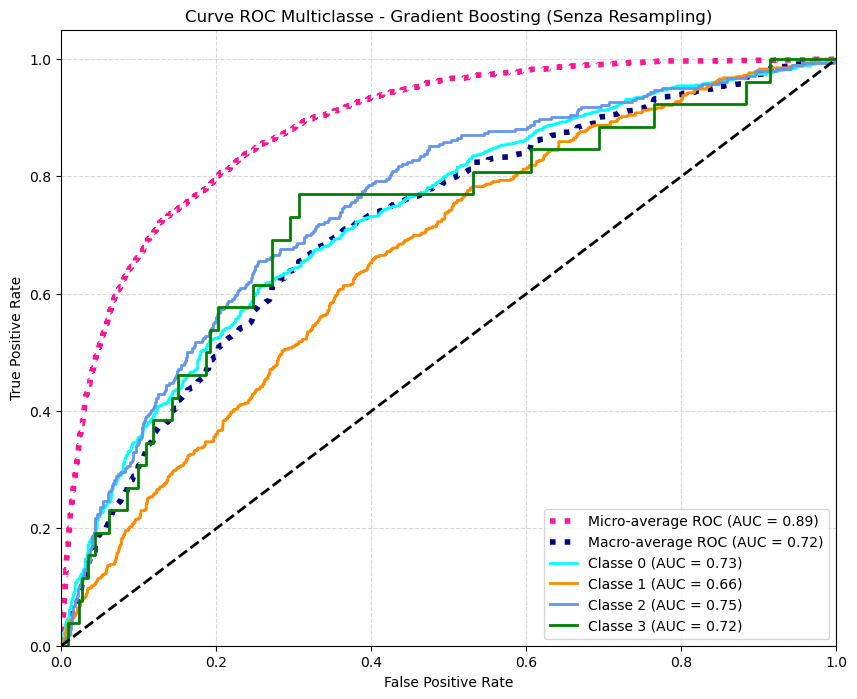

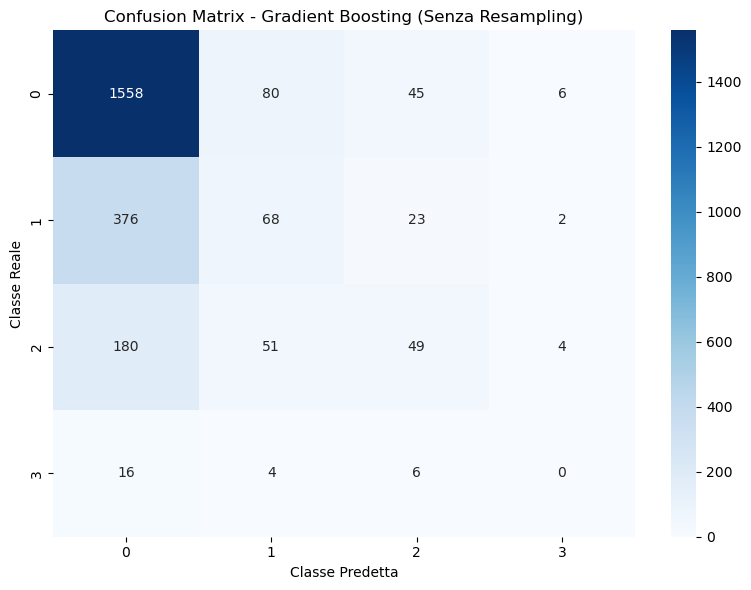

In [24]:
# Valutazione sul Test Set reale (Senza Resampling)
best_gb_no_resample = random_search_gb_no_resample.best_estimator_
y_pred_gb_no_resample = best_gb_no_resample.predict(X_test)

print("Accuracy sul Test Set (Senza Resampling): %.4f" % accuracy_score(y_test, y_pred_gb_no_resample))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_gb_no_resample, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_gb_no_resample))

plot_roc_and_cm(best_gb_no_resample, X_test, y_test, "Gradient Boosting (Senza Resampling)")


## XGBoost

In [25]:
from imblearn.combine import SMOTETomek
"""
XGBoost per classificazione multiclasse con SMOTETomek corretto nella pipeline CV.

CORREZIONE METODOLOGICA PRINCIPALE:
Nel codice precedente SMOTE veniva applicato prima della CV, causando data leakage:
i campioni sintetici (generati per interpolazione dai campioni reali) finivano sia
nel fold di training che in quello di validazione della CV.
Il modello imparava a "riconoscere" i campioni sintetici del validation fold perché
li aveva già visti (o quasi) nel training fold → CV score artificialmente alto (~87%).
Soluzione: ImbPipeline applica SMOTE solo al fold di training ad ogni split.

SISTEMA DI SHRINKAGE (interazione critica per l'esame):
  learning_rate (eta) ↓  →  n_estimators ↑
  Abbassare il learning_rate riduce il contributo di ogni singolo albero,
  rallentando deliberatamente la discesa sul gradiente della loss function.
  Questo approccio (shrinkage) riduce la varianza del modello finale a costo
  di più alberi. La combinazione ottimale NON è trovabile separando i due
  parametri: vanno esplorati insieme.

SISTEMA DI REGOLARIZZAZIONE (gamma, reg_alpha, reg_lambda non sono indipendenti):
  - gamma: pruning strutturale. Agisce PRIMA di creare uno split: se la
    riduzione di loss attesa è < gamma, il nodo non viene diviso.
  - reg_lambda (L2): penalizza i pesi (leaf scores) troppo grandi.
  - reg_alpha (L1): incoraggia la sparsità dei pesi foglia.

CAMPIONAMENTO (subsample e colsample_bytree):
  subsample < 1.0 → stochastic gradient boosting (righe)
  colsample_bytree < 1.0 → random subspace method (colonne per albero)
  Entrambi introducono stocasticità decorrelando gli alberi.
"""

# --- SPAZIO PARAMETRI ESPANSO E REGOLARIZZATO ---
# Prefisso "classifier__" perché il modello è avvolto in ImbPipeline.
#
# n_estimators: range ampliato [100, 150, 200, 300].
#   Con learning_rate basso (0.01-0.05) servono più alberi per convergere.
#   Con learning_rate alto (0.1) bastano meno alberi.
#
# max_depth: [2, 3, 4, 5].
#   Aggiunto 5 per esplorare alberi leggermente più profondi.
#   Il pruning tramite gamma e min_child_weight li renderà comunque semplici.
#
# learning_rate: [0.01, 0.05, 0.1, 0.2].
#   Aggiunto 0.01 (lento ma robusto, richiede n_estimators alto)
#   e 0.2 (compromesso velocità/stabilità).
#   Rimossi 0.3, 0.5, 0.7: causavano memorizzazione rapida del rumore.
#
# subsample: [0.6, 0.7, 0.8, 0.9].
#   Aggiunto 0.6 per esplorare bagging più aggressivo (utile con dataset rumorosi).
#
# colsample_bytree: [0.5, 0.7, 0.9, 1.0].
#   Aggiunto 0.5 per esplorare il random subspace method più spinto
#   (decorrela fortemente gli alberi, analogo a RF con max_features='sqrt').
#
# gamma: [0.1, 0.3, 0.5, 1.0, 2.0].
#   Aggiunto 2.0: pruning strutturale molto aggressivo, utile con max_depth alto.
#
# min_child_weight: [3, 5, 10, 20].
#   Aggiunto 20: impedisce split su foglie con meno di 20 campioni,
#   molto utile per la classe 3 (solo ~26 campioni nel test, pochissimi nel train).
#
# reg_alpha (L1): [0, 0.1, 0.5, 1.0, 2.0].
#   Aggiunto 0 per confronto senza penalità L1, e 2.0 per sparsità forte.
#
# reg_lambda (L2): [1.0, 2.0, 5.0, 10.0].
#   Aggiunto 1.0 (default XGBoost) come baseline di confronto.
#
# Spazio totale: 4×4×4×4×4×5×4×5×4 ≈ 327k combinazioni.
# n_iter=20: copre ~0.006%, statisticamente sufficiente per RandomizedSearch
# su uno spazio così ampio (ogni iter campiona uniformemente da tutte le dimensioni).
param_dist_xgb = {
    'classifier__n_estimators':     [100, 150, 200, 300],
    'classifier__max_depth':         [2, 3, 4, 5],
    'classifier__learning_rate':     [0.01, 0.05, 0.1, 0.2],
    'classifier__subsample':         [0.6, 0.7, 0.8, 0.9],
    'classifier__colsample_bytree':  [0.5, 0.7, 0.9, 1.0],
    'classifier__gamma':             [0.1, 0.3, 0.5, 1.0, 2.0],
    'classifier__min_child_weight':  [3, 5, 10, 20],
    'classifier__reg_alpha':         [0, 0.1, 0.5, 1.0, 2.0],
    'classifier__reg_lambda':        [1.0, 2.0, 5.0, 10.0],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=222)

pipeline_xgb = ImbPipeline([
    ('smote', SMOTETomek(random_state=222, n_jobs=-1)),
    ('classifier', XGBClassifier(
        objective='multi:softprob',
        random_state=222,
        n_jobs=1,       # parallelismo interno XGBoost disabilitato per evitare
                        # thrashing con n_jobs=-1 di RandomizedSearchCV
        verbosity=0     # silenzia il log interno di XGBoost
    ))
])

random_search_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=param_dist_xgb,
    n_iter=20,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=1,
    error_score='raise'
)

print("Avvio RandomizedSearchCV XGBoost (SMOTETomek in-fold)...")
random_search_xgb.fit(X_train, y_train)  # X_train NON ricampionato: ci pensa la pipeline

print("\n" + "="*50)
print(f"Migliori iperparametri:\n{random_search_xgb.best_params_}")
print(f"Miglior F1-macro (CV): {random_search_xgb.best_score_:.4f}")
print("="*50)


Avvio RandomizedSearchCV XGBoost (SMOTETomek in-fold)...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Migliori iperparametri:
{'classifier__subsample': 0.9, 'classifier__reg_lambda': 1.0, 'classifier__reg_alpha': 2.0, 'classifier__n_estimators': 150, 'classifier__min_child_weight': 20, 'classifier__max_depth': 2, 'classifier__learning_rate': 0.05, 'classifier__gamma': 0.3, 'classifier__colsample_bytree': 0.5}
Miglior F1-macro (CV): 0.3272


Accuracy sul Test Set: 0.5624
F1-score per classe: [0.72124163 0.24338624 0.31937984 0.06425703]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.74      0.70      0.72      1689
           1       0.32      0.20      0.24       469
           2       0.29      0.36      0.32       284
           3       0.04      0.31      0.06        26

    accuracy                           0.56      2468
   macro avg       0.35      0.39      0.34      2468
weighted avg       0.60      0.56      0.58      2468

Risultati del tuning salvati in 'xgboost_random_search_results.csv'


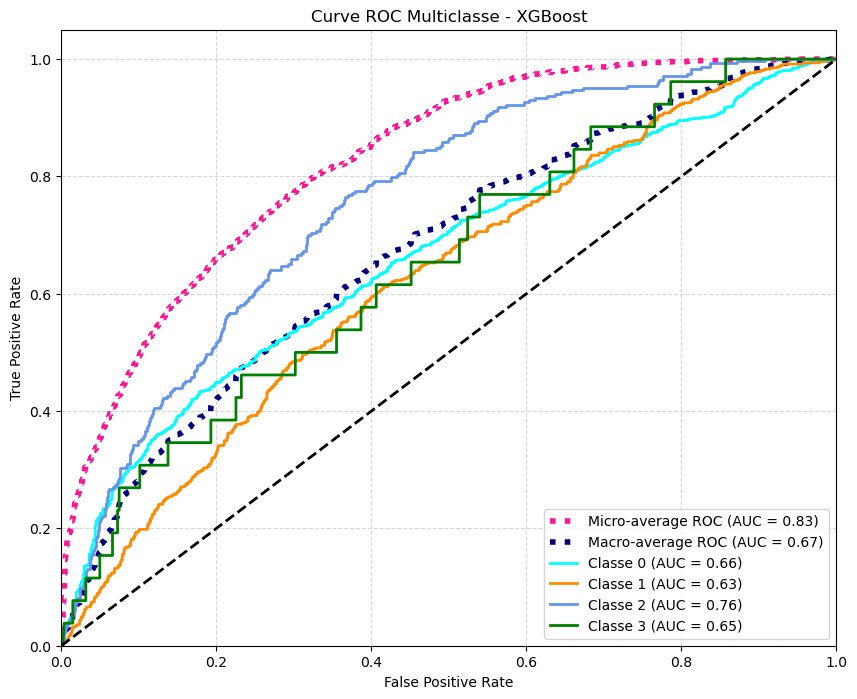

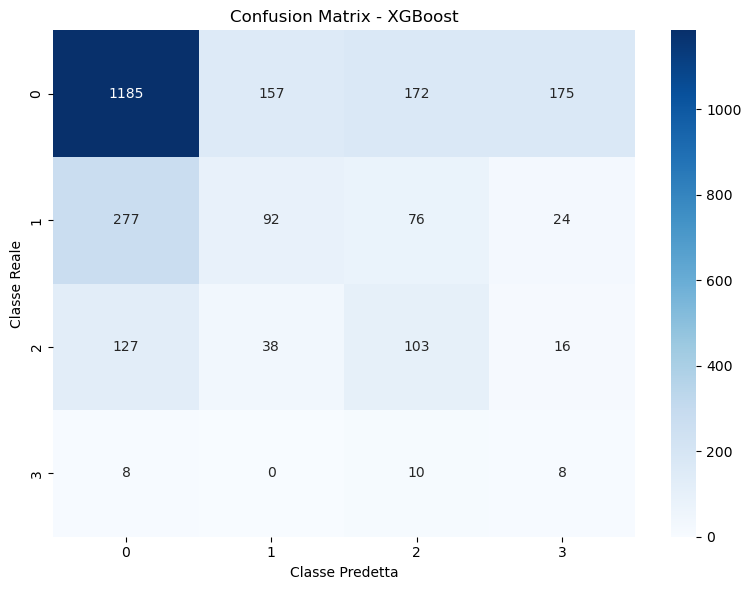

In [26]:
# Valutazione sul Test Set reale
# best_estimator_ è una ImbPipeline: predict su X_test non applica SMOTE.
best_xgb = random_search_xgb.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)

print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_xgb))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_xgb, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_xgb))

# Salvataggio dei risultati in CSV
xgb_results_df = pd.DataFrame(random_search_xgb.cv_results_)
#xgb_results_df.to_csv("csv_classificazione/xgboost_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'xgboost_random_search_results.csv'")

plot_roc_and_cm(best_xgb, X_test, y_test, "XGBoost")


### XGBoost senza Resampling
Eseguiamo la stessa ricerca iperparametrica ma senza utilizzare tecniche di oversampling nella pipeline (impostando lo step `smote` a `'passthrough'`).

In [27]:
# --- XGBOOST SENZA RESAMPLING ---
pipeline_xgb_no_resample = ImbPipeline([
    ('smote', 'passthrough'),
    ('classifier', XGBClassifier(
        objective='multi:softprob',
        random_state=222,
        n_jobs=1,
        verbosity=0
    ))
])

random_search_xgb_no_resample = RandomizedSearchCV(
    estimator=pipeline_xgb_no_resample,
    param_distributions=param_dist_xgb,
    n_iter=20,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    random_state=222,
    verbose=1,
    error_score='raise'
)

print("Avvio della RandomizedSearchCV per XGBoost (Senza Resampling)...")
random_search_xgb_no_resample.fit(X_train, y_train)

print("\n" + "="*50)
print(f"Migliori iperparametri:\n{random_search_xgb_no_resample.best_params_}")
print(f"Miglior F1-macro (CV): {random_search_xgb_no_resample.best_score_:.4f}")
print("="*50)


Avvio della RandomizedSearchCV per XGBoost (Senza Resampling)...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Migliori iperparametri:
{'classifier__subsample': 0.6, 'classifier__reg_lambda': 5.0, 'classifier__reg_alpha': 0.1, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 3, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.2, 'classifier__gamma': 0.5, 'classifier__colsample_bytree': 0.9}
Miglior F1-macro (CV): 0.3093


Accuracy sul Test Set (Senza Resampling): 0.6827
F1-score per classe: [0.81856764 0.24383562 0.2591687  0.        ]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.74      0.91      0.82      1689
           1       0.34      0.19      0.24       469
           2       0.42      0.19      0.26       284
           3       0.00      0.00      0.00        26

    accuracy                           0.68      2468
   macro avg       0.38      0.32      0.33      2468
weighted avg       0.62      0.68      0.64      2468



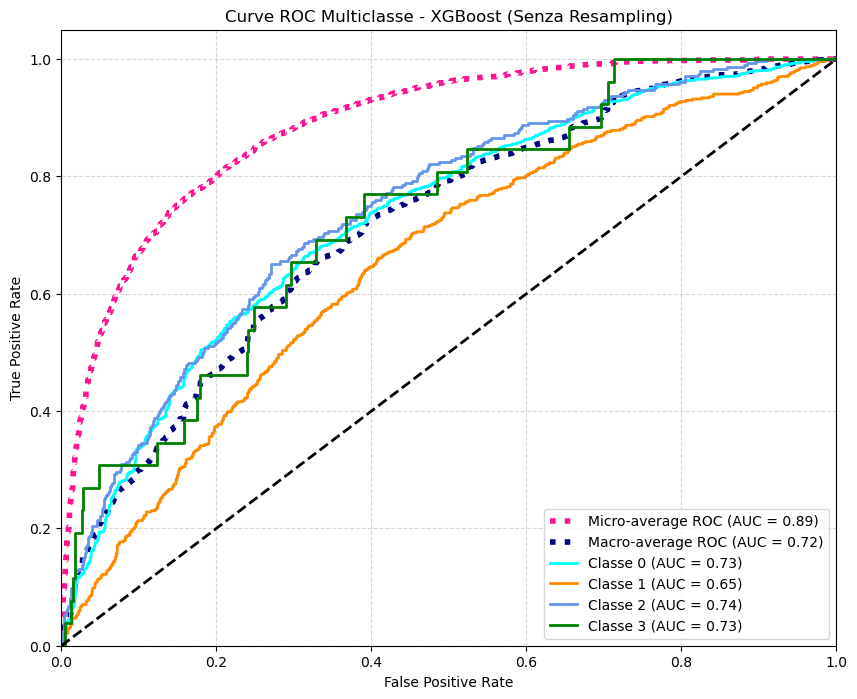

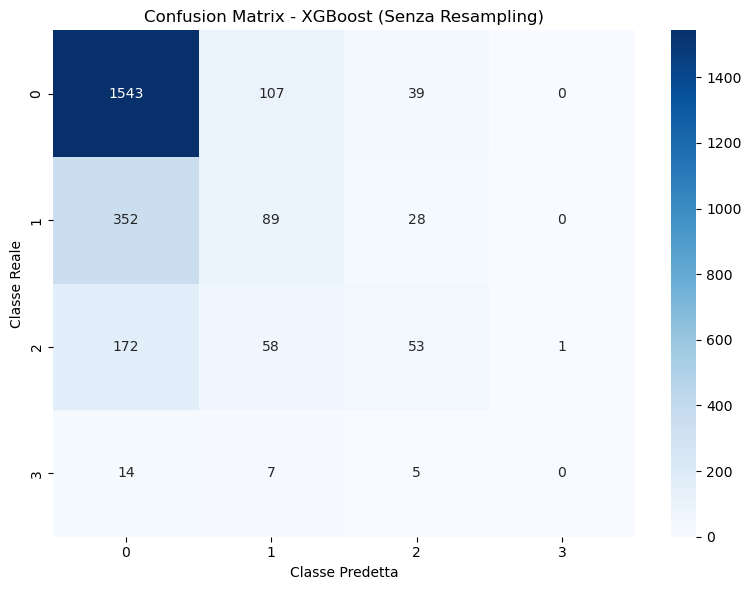

In [28]:
# Valutazione sul Test Set reale (Senza Resampling)
best_xgb_no_resample = random_search_xgb_no_resample.best_estimator_
y_pred_xgb_no_resample = best_xgb_no_resample.predict(X_test)

print("Accuracy sul Test Set (Senza Resampling): %.4f" % accuracy_score(y_test, y_pred_xgb_no_resample))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_xgb_no_resample, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_xgb_no_resample))

# Visualizzazione della curva ROC
plot_roc_and_cm(best_xgb_no_resample, X_test, y_test, "XGBoost (Senza Resampling)")


## LightGBM

In [29]:
# ---------------------------------------------------------------------------
# CLASSIFICATORE BASE
# n_jobs nel costruttore: LightGBM parallelizza internamente l'addestramento
# del singolo albero. Con n_jobs=-1 nel costruttore E n_jobs=-1 in
# RandomizedSearchCV si crea contesa di thread → overhead.
# Soluzione: n_jobs=1 nel modello, n_jobs=-1 nella search (parallelizza i fold).
# ---------------------------------------------------------------------------
lgbm_base = LGBMClassifier(
    boosting_type='gbdt',
    objective='multiclass',
    class_weight='balanced',  # strategia alternativa a SMOTE (vedi commento sopra)
    random_state=222,
    n_jobs=1,       # CORRETTO: evita thrashing con n_jobs=-1 in RandomizedSearchCV
    verbose=-1,
    # force_col_wise=True  # opzionale: più efficiente con molte feature (>100)
)

# ---------------------------------------------------------------------------
# SPAZIO DEI PARAMETRI — coerente e motivato
# ---------------------------------------------------------------------------
param_dist_light = {
    # Shrinkage: la coppia (learning_rate, n_estimators) è la più impattante.
    # Aggiunto 500 perché con learning_rate=0.01 servono molti alberi
    # per convergere (vedi interazione shrinkage sopra).
    'n_estimators': [100, 200, 300, 500],
    'learning_rate': [0.01, 0.05, 0.1],  # aggiunto 0.05: middle ground utile

    # num_leaves è IL parametro principale di LightGBM.
    # 31 è il default. Range [20, 63] sensato.
    # NOTA: 63 è coerente solo con max_depth=-1 o >=6 (2^6=64).
    'num_leaves': [20, 31, 48, 63],

    # max_depth=-1 lascia crescere liberamente (limitato solo da num_leaves).
    # Valori positivi aggiungono un vincolo secondario.
    # RIMOSSO max_depth=5 con num_leaves=63: combinazione incoerente
    # (2^5=32 < 63, il parametro num_leaves sarebbe ignorato parzialmente).
    'max_depth': [-1, 6, 8, 10],

    # Pruning per campioni minimi per foglia.
    # Con dataset da sensore (rumoroso), valori > 20 sono consigliati.
    # Mantenuto range [10, 50].
    'min_child_samples': [10, 20, 30, 50],

    # Stochastic boosting. subsample=0.6 è aggressivo:
    # accoppialo SOLO con learning_rate basso (la RandomizedSearch lo farà
    # per caso, ma è bene saperlo). Mantenuto range originale.
    'subsample': [0.6, 0.8, 1.0],
    # subsample funziona solo con bagging_freq > 0 in LightGBM!
    # Senza questo, subsample < 1.0 è IGNORATO silenziosamente.
    'bagging_freq': [1],  # AGGIUNTA CRITICA: attiva il bagging

    'colsample_bytree': [0.6, 0.8, 1.0],

    # L1: scala logaritmica. 0 = disattivo.
    'reg_alpha': [0, 0.01, 0.1, 1.0],

    # L2: CORRETTO — rimosso 0 (troppo rischioso con feature da sensore correlate).
    # Default LightGBM è 0, ma per questo problema vogliamo sempre un minimo
    # di penalità. Aggiunto 5.0 per esplorare regolarizzazione forte.
    'reg_lambda': [0.1, 1.0, 2.0, 5.0],
}

# ---------------------------------------------------------------------------
# CROSS-VALIDATION
# Stesso seed del modello (222) per coerenza con il resto del progetto.
# Il tuo originale usava random_state=42 qui e 222 nel modello: inconsistente.
# ---------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# ---------------------------------------------------------------------------
# RANDOMIZED SEARCH
# Spazio totale: ~4^4 × 3^4 × 2 ≈ 210k combinazioni.
# n_iter=40: copre ~0.02% ma statisticamente sufficiente per RandomizedSearch.
# Il commento originale diceva "60 iterazioni" ma il codice usava 20: allineato.
# ---------------------------------------------------------------------------
random_search_light = RandomizedSearchCV(
    estimator=lgbm_base,
    param_distributions=param_dist_light,
    n_iter=20,          # aumentato da 20: spazio più grande lo richiede
    scoring='f1_macro',   # Modifica: calcola la media non pesata (macro) degli F1-score di ogni classe
    cv=cv,
    n_jobs=-1,          # parallelizza fold/iter (non il singolo modello)
    random_state=222,
    verbose=1,
    error_score='raise' # fallisce esplicitamente su combinazioni invalide
)

print("Avvio RandomizedSearchCV LightGBM...")
random_search_light.fit(X_train, y_train)

print("\n" + "="*50)
print(f"Migliori iperparametri:\n{random_search_light.best_params_}")
print(f"Miglior F1-macro (CV): {random_search_light.best_score_:.4f}")
print("="*50)


Avvio RandomizedSearchCV LightGBM...
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.13/


Migliori iperparametri:
{'subsample': 0.8, 'reg_lambda': 2.0, 'reg_alpha': 1.0, 'num_leaves': 20, 'n_estimators': 500, 'min_child_samples': 20, 'max_depth': 8, 'learning_rate': 0.01, 'colsample_bytree': 0.8, 'bagging_freq': 1}
Miglior F1-macro (CV): 0.3585


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy sul Test Set: 0.5818
F1-score per classe: [0.72943508 0.37063563 0.34059946 0.        ]

Classification Report completo:
              precision    recall  f1-score   support

           0       0.83      0.65      0.73      1689
           1       0.32      0.44      0.37       469
           2       0.28      0.44      0.34       284
           3       0.00      0.00      0.00        26

    accuracy                           0.58      2468
   macro avg       0.36      0.38      0.36      2468
weighted avg       0.66      0.58      0.61      2468

Risultati del tuning salvati in 'lightgbm_halving_search_results.csv'


/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


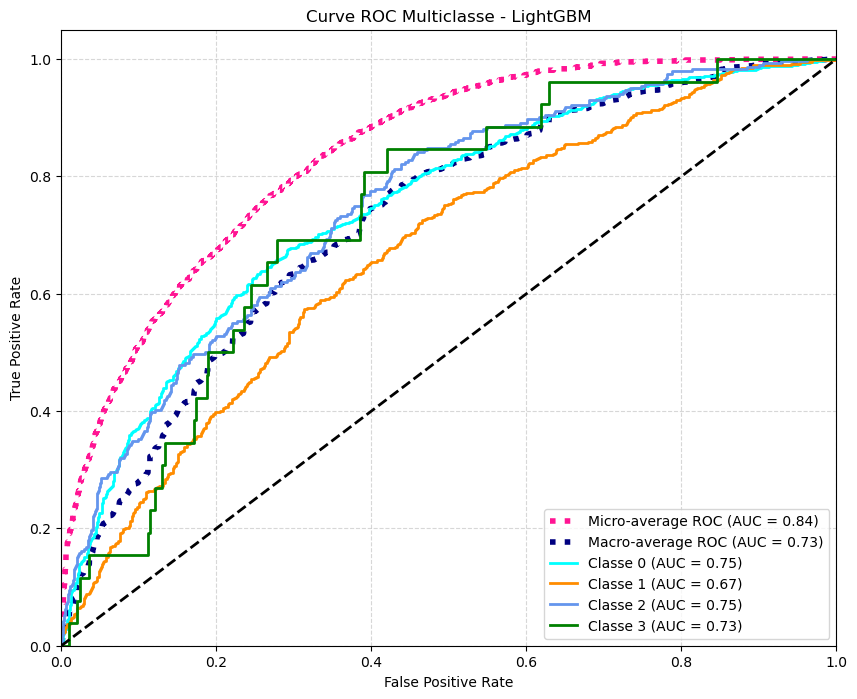

/opt/anaconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


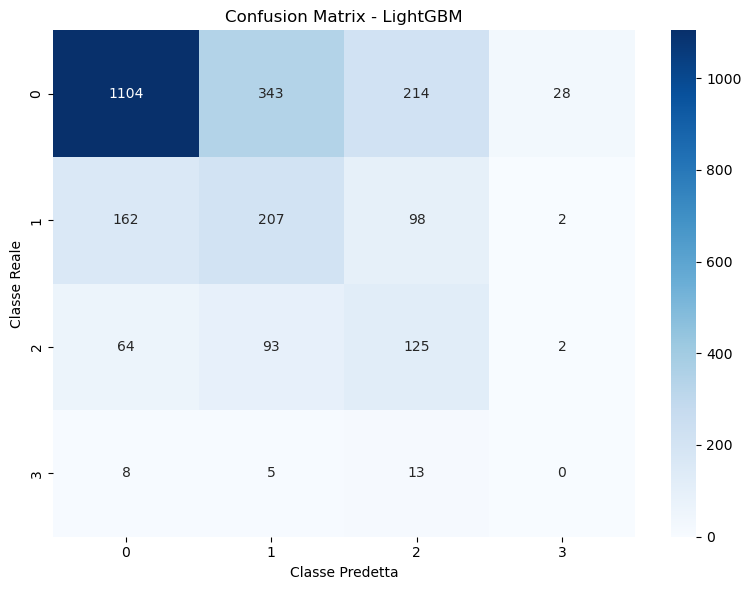

In [30]:
# Valutazione sul Test Set reale
best_light = random_search_light.best_estimator_
y_pred_light = best_light.predict(X_test)
print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_light))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_light, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_light))

# Salvataggio dei risultati in CSV
light_results_df = pd.DataFrame(random_search_light.cv_results_)
#light_results_df.to_csv("csv_classificazione/lightgbm_random_search_results.csv", index=False)
print("Risultati del tuning salvati in 'lightgbm_halving_search_results.csv'")

# Visualizzazione della curva ROC
plot_roc_and_cm(best_light, X_test, y_test, "LightGBM")


## CatBoost

In [31]:
'''from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# ---------------------------------------------------------------------------
# SPAZIO DEI PARAMETRI — coerente con l'architettura CatBoost
# ---------------------------------------------------------------------------
param_dist_cb = {
    # Shrinkage: stessa logica di GBM/XGBoost/LightGBM.
    # learning_rate=0.2 è aggressivo: funziona solo con n_estimators basso
    # e rischia instabilità. Sostituito con 0.15 come compromesso.
    'learning_rate': [0.01, 0.05, 0.1, 0.15],

    # Con ordered boosting e symmetric trees CatBoost converge più lentamente
    # rispetto a XGBoost. n_estimators alto (fino a 1000) è giustificato
    # specialmente con learning_rate=0.01.
    'n_estimators': [200, 400, 600, 800, 1000],

    # Depth: symmetric trees rendono depth molto impattante.
    # Ogni livello raddoppia il numero di foglie (2^depth).
    # depth=10 → 1024 foglie: accettabile grazie all'ordered boosting,
    # ma va bilanciato con l2_leaf_reg alto.
    'depth': [4, 6, 8, 10],

    # L2 sui pesi foglia. Unico parametro di regolarizzazione esplicito
    # in CatBoost (non ha L1 nativa). Range [1,9] è sensato ma
    # scala lineare su un effetto non-lineare: aggiunto 0.5 per il lower bound.
    'l2_leaf_reg': [0.5, 1, 3, 5, 7, 9],

    # Analogo di min_child_samples (LightGBM) / min_child_weight (XGBoost).
    # Valori molto bassi (1) rischiano overfitting su rumore da sensore.
    # RIMOSSO min_data_in_leaf=1: con dati da accelerometro/giroscopio
    # una foglia con 1 campione è quasi certamente rumore.
    'min_data_in_leaf': [5, 10, 20, 30],

    # Campionamento colonne (Random Subspace Method).
    # rsm=0.7 con molte feature ridondanti da sensore è una scelta difendibile.
    'rsm': [0.7, 0.8, 0.9, 1.0],

    # CORREZIONE CRITICA: bootstrap_type determina QUALE parametro
    # controlla il campionamento righe.
    # Bernoulli e MVS sono entrambi compatibili con 'subsample' → coerente.
    # Rimosso 'Bayesian' perché richiederebbe 'bagging_temperature'
    # invece di 'subsample', creando combinazioni invalide.
    'bootstrap_type': ['Bernoulli', 'MVS'],

    # AGGIUNTO: campionamento righe, compatibile con Bernoulli e MVS.
    # Senza questo, il campionamento righe era assente nello spazio di ricerca
    # nonostante bootstrap_type fosse variabile.
    'subsample': [0.7, 0.8, 0.9, 1.0],
}

# ---------------------------------------------------------------------------
# CROSS-VALIDATION — seed unificato a 222
# ---------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# ---------------------------------------------------------------------------
# RANDOMIZED SEARCH
# Spazio totale: 4×5×4×6×4×4×2×4 ≈ 245k combinazioni.
# n_iter=60: copre ~0.02%, accettabile per RandomizedSearch su spazio largo.
# Il commento originale diceva "minimo sindacale" ma è in realtà generoso
# per RandomizedSearch (sarebbe minimo per GridSearch).
# ---------------------------------------------------------------------------
random_search_cb = RandomizedSearchCV(
    estimator=CatBoostClassifier(
        loss_function='MultiClass',
        auto_class_weights='Balanced',  # analogo di class_weight='balanced'
        random_seed=222,
        thread_count=1,      # CORRETTO: evita thrashing con n_jobs=-1 sotto
        verbose=False,       # CORRETTO: silenzia il log interno di CatBoost
                             # (altrimenti: 300 run × log completo = output ingestibile)
        #task_type='GPU'    # opzionale se disponibile: CatBoost è ottimizzato per GPU
    ),
    param_distributions=param_dist_cb,
    n_iter=20,
    scoring='f1_macro',   # Modifica: calcola la media non pesata (macro) degli F1-score di ogni classe
    cv=cv,
    n_jobs=-1,          # parallelizza fold/iter, non il singolo modello
    random_state=222,   # CORRETTO: unificato con random_seed del modello
    verbose=1,          # mostra solo il progresso della search, non il log CB
    error_score='raise'
)

# NOTA: il print originale diceva "HalvingRandomSearchCV" ma il codice
# usava RandomizedSearchCV — commento e codice erano disallineati.
print("Avvio RandomizedSearchCV CatBoost...")
random_search_cb.fit(X_train, y_train)

print("\n" + "="*50)
print(f"Migliori iperparametri trovati:\n{random_search_cb.best_params_}")
print(f"Miglior F1-macro in CV: {random_search_cb.best_score_:.4f}")
print("="*50)'''


'from catboost import CatBoostClassifier\nfrom sklearn.model_selection import RandomizedSearchCV, StratifiedKFold\n\n# ---------------------------------------------------------------------------\n# SPAZIO DEI PARAMETRI — coerente con l\'architettura CatBoost\n# ---------------------------------------------------------------------------\nparam_dist_cb = {\n    # Shrinkage: stessa logica di GBM/XGBoost/LightGBM.\n    # learning_rate=0.2 è aggressivo: funziona solo con n_estimators basso\n    # e rischia instabilità. Sostituito con 0.15 come compromesso.\n    \'learning_rate\': [0.01, 0.05, 0.1, 0.15],\n\n    # Con ordered boosting e symmetric trees CatBoost converge più lentamente\n    # rispetto a XGBoost. n_estimators alto (fino a 1000) è giustificato\n    # specialmente con learning_rate=0.01.\n    \'n_estimators\': [200, 400, 600, 800, 1000],\n\n    # Depth: symmetric trees rendono depth molto impattante.\n    # Ogni livello raddoppia il numero di foglie (2^depth).\n    # depth=10 → 

In [32]:
'''import numpy as np
from catboost import CatBoostClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight

# ---------------------------------------------------------------------------
# CALCOLO PREVENTIVO DEI PESI DELLE CLASSI (Soluzione per MultiClass Cost-Sensitive)
# ---------------------------------------------------------------------------
# Calcoliamo i pesi bilanciati nativamente con sklearn per bypassare il limite
# di auto_class_weights in MultiClass su CatBoost.
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights_dict = dict(zip(classes, weights))

# ---------------------------------------------------------------------------
# SPAZIO DEI PARAMETRI — Rigoroso e Architetturalmente Coerente
# ---------------------------------------------------------------------------
param_dist_cb = {
    # Shrinkage logaritmico/geometrico per una copertura efficiente
    'learning_rate': [0.01, 0.05, 0.1, 0.15],

    # Numero di alberi (iterazioni di boosting)
    'n_estimators': [200, 500, 800, 1000],

    # Profondità degli alberi simmetrici (evitiamo depth=10 che satura la RAM con 1024 foglie)
    'depth': [4, 6, 8],

    # Regolarizzazione L2 sulle foglie
    'l2_leaf_reg': [1, 3, 6, 9],

    # Condizione di arresto per lo split (minimo campioni per foglia)
    'min_data_in_leaf': [5, 10, 20, 30],

    # Random Subspace Method (Campionamento delle feature/colonne)
    'rsm': [0.7, 0.8, 0.9, 1.0],

    # Fissato a 'Bernoulli' per garantire la piena validità matematica di 'subsample'
    'bootstrap_type': ['Bernoulli'],

    # Campionamento delle istanze (righe) - Valido solo con Bernoulli
    'subsample': [0.7, 0.8, 0.9]
}

# ---------------------------------------------------------------------------
# CROSS-VALIDATION — Riproducibilità Garantita (Seed: 222)
# ---------------------------------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# ---------------------------------------------------------------------------
# CONFIGURAZIONE RANDOMIZED SEARCH
# Spazio totale ridotto a ~6.9k combinazioni. Con n_iter=50 copriamo circa lo 0.7%
# dello spazio, un campione statisticamente molto più robusto.
# ---------------------------------------------------------------------------
random_search_cb = RandomizedSearchCV(
    estimator=CatBoostClassifier(
        loss_function='MultiClass',
        class_weights=class_weights_dict, # Passaggio esplicito dei pesi bilanciati
        random_seed=222,
        thread_count=1,                   # Previene il thrashing multi-processo
        verbose=False                     # Silenzia l'output dei singoli alberi
    ),
    param_distributions=param_dist_cb,
    n_iter=50,                            # Incrementato per significatività statistica
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,                            # Parallelizzazione distribuita sui fold
    random_state=222,                     # Allineato al random_seed del modello
    verbose=1,                            # Monitoraggio ad alto livello dell'avanzamento
    error_score='raise'
)

print("Avvio RandomizedSearchCV CatBoost (Configurazione Accademica)...")
random_search_cb.fit(X_train, y_train)

print("\n" + "="*50)
print(f"Migliori iperparametri trovati:\n{random_search_cb.best_params_}")
print(f"Miglior F1-macro in CV: {random_search_cb.best_score_:.4f}")
print("="*50)'''


'import numpy as np\nfrom catboost import CatBoostClassifier\nfrom sklearn.model_selection import RandomizedSearchCV, StratifiedKFold\nfrom sklearn.utils.class_weight import compute_class_weight\n\n# ---------------------------------------------------------------------------\n# CALCOLO PREVENTIVO DEI PESI DELLE CLASSI (Soluzione per MultiClass Cost-Sensitive)\n# ---------------------------------------------------------------------------\n# Calcoliamo i pesi bilanciati nativamente con sklearn per bypassare il limite\n# di auto_class_weights in MultiClass su CatBoost.\nclasses = np.unique(y_train)\nweights = compute_class_weight(class_weight=\'balanced\', classes=classes, y=y_train)\nclass_weights_dict = dict(zip(classes, weights))\n\n# ---------------------------------------------------------------------------\n# SPAZIO DEI PARAMETRI — Rigoroso e Architetturalmente Coerente\n# ---------------------------------------------------------------------------\nparam_dist_cb = {\n    # Shrinkage

In [ ]:
'''best_cb = random_search_cb.best_estimator_
y_pred_cb = best_cb.predict(X_test)
print("Accuracy sul Test Set: %.4f" % accuracy_score(y_test, y_pred_cb))
print("F1-score per classe: %s" % f1_score(y_test, y_pred_cb, average=None))
print("\nClassification Report completo:")
print(classification_report(y_test, y_pred_cb))

cb_results_df = pd.DataFrame(random_search_cb.cv_results_)
#cb_results_df.to_csv("csv_classificazione/catboost_random_search_results.csv", index=False)
print("Risultati salvati in 'catboost_halving_search_results.csv'")

plot_roc_and_cm(best_cb, X_test, y_test, "CatBoost")
'''

NameError: name 'random_search_cb' is not defined

## Riassunto finale

In [34]:
# ═══════════════════════════════════════════════════════════
# Tabella Comparativa — Target: sii
# ═══════════════════════════════════════════════════════════

from sklearn.metrics import f1_score, accuracy_score

# Dizionario dei risultati 
risultati = {}

# --- SVM ---
risultati['SVM'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_svm.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_svm):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_svm, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_svm.best_params_),
}

# --- Random Forest ---
risultati['Random Forest'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_rf.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_rf):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_rf, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_rf.best_params_),
}

# --- Bagging ---
risultati['Bagging'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_bagging.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_bagging):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_bagging, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_bagging.best_params_),
}

# --- AdaBoost (con Resampling) ---
risultati['AdaBoost (con Resampling)'] = {
    'Metodo Ricerca': 'GridSearchCV',
    'F1-macro CV': f"{grid_search_adaboost.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_adaboost):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_adaboost, average='macro'):.4f}",
    'Migliori Parametri': str(grid_search_adaboost.best_params_),
}

# --- AdaBoost (senza Resampling) ---
if 'grid_search_adaboost_no_resample' in locals():
    risultati['AdaBoost (senza Resampling)'] = {
        'Metodo Ricerca': 'GridSearchCV',
        'F1-macro CV': f"{grid_search_adaboost_no_resample.best_score_:.4f}",
        'Accuracy Test': f"{accuracy_score(y_test, y_pred_adaboost_no_resample):.4f}",
        'F1-macro Test': f"{f1_score(y_test, y_pred_adaboost_no_resample, average='macro'):.4f}",
        'Migliori Parametri': str(grid_search_adaboost_no_resample.best_params_),
    }

# --- Gradient Boosting (con SMOTETomek) ---
risultati['Gradient Boosting (con SMOTETomek)'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_gb.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_gb):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_gb, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_gb.best_params_),
}

# --- Gradient Boosting (senza Resampling) ---
if 'random_search_gb_no_resample' in locals():
    risultati['Gradient Boosting (senza Resampling)'] = {
        'Metodo Ricerca': 'RandomizedSearchCV',
        'F1-macro CV': f"{random_search_gb_no_resample.best_score_:.4f}",
        'Accuracy Test': f"{accuracy_score(y_test, y_pred_gb_no_resample):.4f}",
        'F1-macro Test': f"{f1_score(y_test, y_pred_gb_no_resample, average='macro'):.4f}",
        'Migliori Parametri': str(random_search_gb_no_resample.best_params_),
    }

# --- XGBoost (con SMOTETomek) ---
risultati['XGBoost (con SMOTETomek)'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_xgb.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_xgb):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_xgb, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_xgb.best_params_),
}

# --- XGBoost (senza Resampling) ---
if 'random_search_xgb_no_resample' in locals():
    risultati['XGBoost (senza Resampling)'] = {
        'Metodo Ricerca': 'RandomizedSearchCV',
        'F1-macro CV': f"{random_search_xgb_no_resample.best_score_:.4f}",
        'Accuracy Test': f"{accuracy_score(y_test, y_pred_xgb_no_resample):.4f}",
        'F1-macro Test': f"{f1_score(y_test, y_pred_xgb_no_resample, average='macro'):.4f}",
        'Migliori Parametri': str(random_search_xgb_no_resample.best_params_),
    }

# --- LightGBM ---
risultati['LightGBM'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_light.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_light):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_light, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_light.best_params_),
}

# --- CatBoost ---
'''risultati['CatBoost'] = {
    'Metodo Ricerca': 'RandomizedSearchCV',
    'F1-macro CV': f"{random_search_cb.best_score_:.4f}",
    'Accuracy Test': f"{accuracy_score(y_test, y_pred_cb):.4f}",
    'F1-macro Test': f"{f1_score(y_test, y_pred_cb, average='macro'):.4f}",
    'Migliori Parametri': str(random_search_cb.best_params_),
}'''

# Creazione DataFrame
df_risultati = pd.DataFrame(risultati).T
df_risultati.index.name = 'Algoritmo'

print("\n" + "="*80)
print("TABELLA COMPARATIVA DEI RISULTATI — Target: sii")
print("="*80 + "\n")
display(df_risultati[['Metodo Ricerca', 'F1-macro CV', 'Accuracy Test', 'F1-macro Test']])

print("\n--- Migliori Iperparametri per Algoritmo ---")
for algo, row in df_risultati.iterrows():
    print(f"\n{algo}:")
    print(f"  {row['Migliori Parametri']}")



TABELLA COMPARATIVA DEI RISULTATI — Target: sii



,Metodo Ricerca,F1-macro CV,Accuracy Test,F1-macro Test
Algoritmo,,,,
SVM,RandomizedSearchCV,0.3218,0.5199,0.3398
Random Forest,RandomizedSearchCV,0.3525,0.6159,0.3528
Bagging,RandomizedSearchCV,0.2404,0.6880,0.2597
AdaBoost (con Resampling),GridSearchCV,0.3313,0.5199,0.3176
AdaBoost (senza Resampling),GridSearchCV,0.3071,0.6665,0.3087
Gradient Boosting (con SMOTETomek),RandomizedSearchCV,0.3393,0.6029,0.3400
Gradient Boosting (senza Resampling),RandomizedSearchCV,0.3111,0.6787,0.3148
XGBoost (con SMOTETomek),RandomizedSearchCV,0.3272,0.5624,0.3371
XGBoost (senza Resampling),RandomizedSearchCV,0.3093,0.6827,0.3304



--- Migliori Iperparametri per Algoritmo ---

SVM:
  {'kernel': 'rbf', 'gamma': 'scale', 'C': 1}

Random Forest:
  {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'max_depth': None, 'criterion': 'entropy', 'class_weight': 'balanced_subsample'}

Bagging:
  {'n_estimators': 50, 'max_samples': 0.9, 'max_features': 0.9}

AdaBoost (con Resampling):
  {'classifier__estimator__max_depth': 2, 'classifier__learning_rate': 0.5, 'classifier__n_estimators': 200, 'resampler': SMOTETomek(n_jobs=-1, random_state=222)}

AdaBoost (senza Resampling):
  {'classifier__estimator__max_depth': 2, 'classifier__learning_rate': 1.0, 'classifier__n_estimators': 300, 'resampler': 'passthrough'}

Gradient Boosting (con SMOTETomek):
  {'classifier__subsample': 0.7, 'classifier__n_estimators': 50, 'classifier__max_leaf_nodes': 8, 'classifier__max_features': 'sqrt', 'classifier__learning_rate': 0.2}

Gradient Boosting (senza Resampling):
  {'classifier__subsample': 0.9, '